<a href="https://colab.research.google.com/github/JuliPerezE/SRA-TP-Filtros-Grupo5/blob/main/notebooks%5C04_Ecualizador_de_Fase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

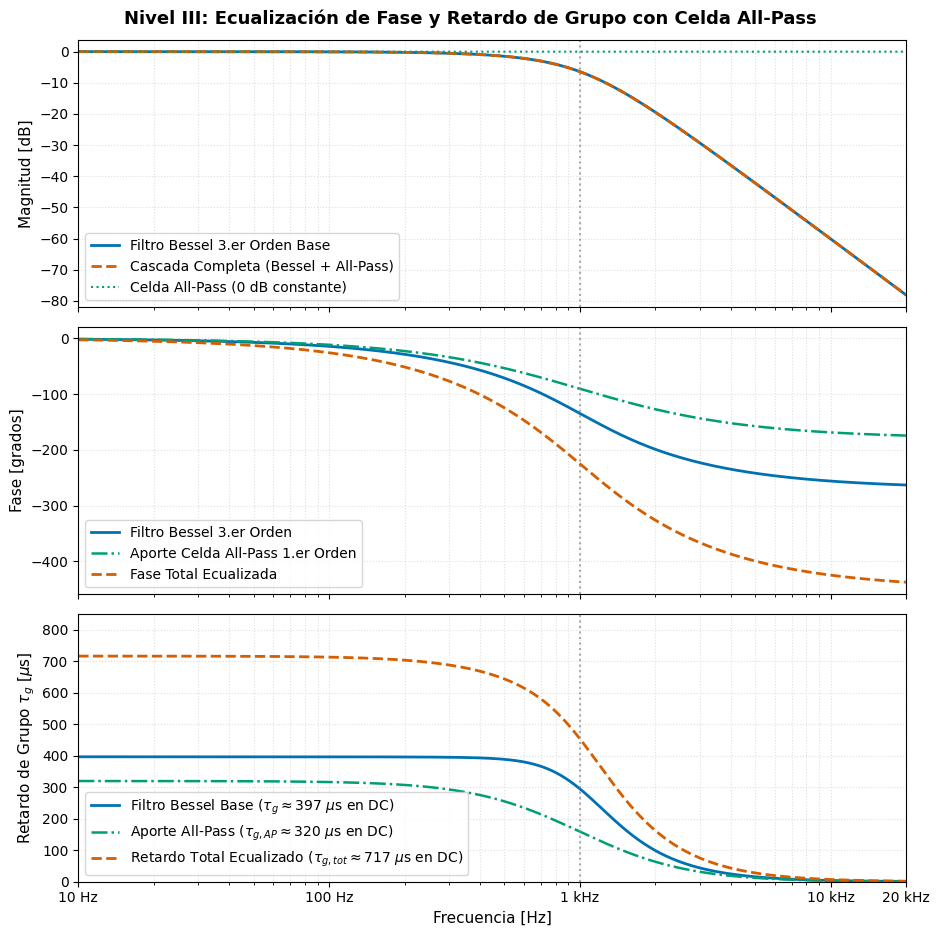

In [2]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

# --- 1. FILTRO PASABAJOS BESSEL DE 3.er ORDEN (BASE) ---
R0, C0 = 16.9e3, 10e-9
R1, R2 = 6.8e3, 16e3
C1, C2 = 22e-9, 10e-9

num_bessel = [1.0]
den_bessel = [R0*R1*R2*C0*C1*C2, R0*C0*C2*(R1+R2) + R1*R2*C1*C2, R0*C0 + C2*(R1+R2), 1.0]
sys_bessel = signal.TransferFunction(num_bessel, den_bessel)

# --- 2. CELDA ALL-PASS DE 1.er ORDEN (Ra = 16 kOhm, Ca = 10 nF) ---
Ra, Ca = 16.0e3, 10.0e-9
wa = 1.0 / (Ra * Ca)

num_ap = [-1.0 / wa, 1.0]
den_ap = [1.0 / wa, 1.0]
sys_ap = signal.TransferFunction(num_ap, den_ap)

# --- 3. CASCADA COMPLETA (Bessel + All-Pass) ---
num_tot = np.polymul(num_bessel, num_ap)
den_tot = np.polymul(den_bessel, den_ap)
sys_tot = signal.TransferFunction(num_tot, den_tot)

# Barrido de frecuencias (10 Hz a 20 kHz)
freq = np.logspace(1, 4.3, 1500)
w = 2 * np.pi * freq

# Respuestas en frecuencia (Bode)
_, mag_bessel, phase_bessel = signal.bode(sys_bessel, w)
_, mag_ap, phase_ap = signal.bode(sys_ap, w)
_, mag_tot, phase_tot = signal.bode(sys_tot, w)

# Retardo de Grupo en microsegundos (tau_g = - d(phi) / d(w))
tau_bessel = -np.gradient(np.radians(phase_bessel), w) * 1e6
tau_ap = -np.gradient(np.radians(phase_ap), w) * 1e6
tau_tot = -np.gradient(np.radians(phase_tot), w) * 1e6

# --- 4. GRÁFICO COMPARATIVO EN 3 PANELLES ---
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9.5, 9.5), sharex=True)

# Panel 1: Magnitud
ax1.semilogx(freq, mag_bessel, label='Filtro Bessel 3.er Orden Base', color='#0072b2', lw=2)
ax1.semilogx(freq, mag_tot, label='Cascada Completa (Bessel + All-Pass)', color='#d55e00', ls='--', lw=2)
ax1.semilogx(freq, mag_ap, label='Celda All-Pass (0 dB constante)', color='#009e73', ls=':', lw=1.5)
ax1.set_ylabel('Magnitud [dB]', fontsize=11)
ax1.axvline(1000, color='#8a8a8a', ls=':', alpha=0.7)
ax1.grid(True, which='both', ls=':', alpha=0.4)
ax1.legend(loc='lower left')

# Panel 2: Fase
ax2.semilogx(freq, phase_bessel, label='Filtro Bessel 3.er Orden', color='#0072b2', lw=2)
ax2.semilogx(freq, phase_ap, label='Aporte Celda All-Pass 1.er Orden', color='#009e73', ls='-.', lw=1.8)
ax2.semilogx(freq, phase_tot, label='Fase Total Ecualizada', color='#d55e00', ls='--', lw=2)
ax2.set_ylabel('Fase [grados]', fontsize=11)
ax2.axvline(1000, color='#8a8a8a', ls=':', alpha=0.7)
ax2.grid(True, which='both', ls=':', alpha=0.4)
ax2.legend(loc='lower left')

# Panel 3: Retardo de Grupo
ax3.semilogx(freq, tau_bessel, label=r'Filtro Bessel Base ($\tau_g \approx 397\ \mu$s en DC)', color='#0072b2', lw=2)
ax3.semilogx(freq, tau_ap, label=r'Aporte All-Pass ($\tau_{g,AP} \approx 320\ \mu$s en DC)', color='#009e73', ls='-.', lw=1.8)
ax3.semilogx(freq, tau_tot, label=r'Retardo Total Ecualizado ($\tau_{g,tot} \approx 717\ \mu$s en DC)', color='#d55e00', ls='--', lw=2)
ax3.set_xlim(10, 20000)
ax3.set_ylim(0, 850)
ax3.set_xlabel('Frecuencia [Hz]', fontsize=11)
ax3.set_ylabel(r'Retardo de Grupo $\tau_g$ [$\mu$s]', fontsize=11)
ax3.axvline(1000, color='#8a8a8a', ls=':', alpha=0.7)
ax3.grid(True, which='both', ls=':', alpha=0.4)
ax3.legend(loc='lower left')

ticks = [10, 100, 1000, 10000, 20000]
tick_labels = ['10 Hz', '100 Hz', '1 kHz', '10 kHz', '20 kHz']
ax3.set_xticks(ticks)
ax3.set_xticklabels(tick_labels)

fig.suptitle('Nivel III: Ecualización de Fase y Retardo de Grupo con Celda All-Pass', fontsize=13, fontweight='bold')
plt.tight_layout()

# Guarda el archivo de imagen para exportar a LaTeX
plt.savefig('ecualizador_allpass_nivel3.png', dpi=200)
plt.show()